# Machine Learning – Practical Session 4
## Overfitting, Data Leakage, and Model Generalization
**National Higher School of Advanced Technologies**  
**Academic Year 2026–2027 | First-year Master's degree**

---

### Objectives & Ground Rules
- **Inspect** data for duplicates, missing values, rare categories, and temporal patterns.
- **Detect & Measure** data leakage caused by inappropriate splitting, duplicate observations, and preprocessing.
- **Diagnose** overfitting using training vs. testing errors and model/feature complexity curves.
- **Improve Generalization** via regularization, feature selection, and model complexity control.
- **Strict Ground Rules**:
  1. Fixed random seed (`random_state=42`) for full reproducibility.
  2. Chronological split (first 80% train, last 20% test) established once and reused.
  3. Preprocessing (imputation, scaling, encoding) strictly inside `scikit-learn` `Pipeline`s.
  4. Test set kept untouched until final evaluation in Part D.4; all model selection done with `TimeSeriesSplit` (5 folds) on the training set.

---
## 0. Environment Setup and Library Imports
We load all required standard scientific computing, data manipulation, visualization, and `scikit-learn` libraries.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-Learn tools
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, r2_score

# Set plotting aesthetics and random seed
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment configured successfully. Random seed fixed to 42.")

Environment configured successfully. Random seed fixed to 42.


---
## 1. Dataset Loading, Encoding, and Inspection (Part A)

### Context & Encodings (Section 2)
The dataset represents 1,200 student survey responses submitted between March 15 and April 14, 2026.
As specified in Section 2:
- Target: `cgpa_category` mapped to numeric midpoint `final_cgpa`:
  - `5.0–6.9` $\rightarrow$ **5.95**
  - `7.0–8.4` $\rightarrow$ **7.70**
  - `8.5–9.4` $\rightarrow$ **8.95**
  - `9.5–10.0` $\rightarrow$ **9.75**
- Ordinal & Interval Features:
  - `study_hours_daily` (renamed `study_hours`): `<1h` $\rightarrow$ 0.5, `1–2h` $\rightarrow$ 1.5, `>2h` $\rightarrow$ 2.5
  - `sleep_hours`: `4–5h` $\rightarrow$ 4.5, `6–7h` $\rightarrow$ 6.5, `>8h` $\rightarrow$ 8.5
  - `attendance_percentage` (renamed `attendance_rate`): `<50%` $\rightarrow$ 40, `50–65%` $\rightarrow$ 57.5, `66–75%` $\rightarrow$ 70.5, `76–85%` $\rightarrow$ 80.5, `>85%` $\rightarrow$ 92.5
  - `study_consistency`: `Rarely` $\rightarrow$ 0, `Sometimes` $\rightarrow$ 1, `Mostly consistent` $\rightarrow$ 2
  - `tasks_on_time`, `assignments_on_time`: `Rarely` $\rightarrow$ 0, `Sometimes` $\rightarrow$ 1, `Often` $\rightarrow$ 2, `Always` $\rightarrow$ 3
  - `revision_frequency`: `Never` $\rightarrow$ 0, `Rarely` $\rightarrow$ 1, `Few times a week` $\rightarrow$ 2, `Daily` $\rightarrow$ 3
  - `career_goal_clarity`: `Not clear` $\rightarrow$ 0, `Somewhat clear` $\rightarrow$ 1, `Very clear` $\rightarrow$ 2
  - `daily_productivity`, `stress_level`, `age`: Already numeric
  - `cohort_code`: `program_stream + " | " + year_class` (42 categories)
  - `effort_index`: mean of normalized effort components (`study_hours/2.5`, `attendance_rate/100`, `study_consistency/2`, `tasks_on_time/3`, `assignments_on_time/3`, `revision_frequency/3`), skipping missing values.

In [2]:
# Locate CSV file (relative path)
csv_filename = "hybrid_student_performance_1200.csv" if os.path.exists("hybrid_student_performance_1200.csv") else "student_performance.csv"
raw_df = pd.read_csv(csv_filename)

print(f"Loaded dataset from: '{csv_filename}'")
print(f"Dimensions: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")

Loaded dataset from: 'hybrid_student_performance_1200.csv'
Dimensions: 1200 rows, 36 columns


### Part A.1: Data Inspection
We inspect data types, descriptive statistics, and missing values across all columns.

In [3]:
# Clean string values (normalize unicode dashes)
def clean_str(val):
    if pd.isna(val):
        return val
    return str(val).replace('–', '-').replace('–', '-').strip()

df = raw_df.copy()
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].apply(clean_str)

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Missing values report
missing_series = df.isna().sum()
missing_pct = (missing_series / len(df)) * 100
missing_report = pd.DataFrame({
    'Missing Count': missing_series[missing_series > 0],
    'Percentage (%)': missing_pct[missing_pct > 0]
}).sort_values(by='Missing Count', ascending=False)

print("Columns with missing values:")
print(missing_report.to_string())
print(f"\nTimestamp range: {df['timestamp'].min()} to {df['timestamp'].max()}")

Columns with missing values:
                        Missing Count  Percentage (%)
events_participation               58        4.833333
sleep_hours                        55        4.583333
external_resources                 45        3.750000
focus_duration                     43        3.583333
routine_rating                     41        3.416667
programming_foundation             41        3.416667
online_courses                     36        3.000000
stress_level                       35        2.916667
daily_productivity                 34        2.833333
revision_frequency                 34        2.833333
screen_time_non_study              32        2.666667
external_pressure                  29        2.416667
energy_level                       28        2.333333

Timestamp range: 2026-03-15 01:07:00 to 2026-04-14 22:27:00


### Part A.2: Duplicate Detection
We detect duplicate observations with `duplicated()` across multiple scopes:
1. Exact duplicates across all columns (including `student_id`).
2. Duplicates without `student_id`.
3. Duplicates ignoring `timestamp`.
4. Duplicates ignoring both `student_id` and `timestamp`.

In [4]:
dup_all = df.duplicated().sum()
dup_no_id = df.drop(columns=['student_id']).duplicated().sum()
dup_no_ts = df.drop(columns=['timestamp']).duplicated().sum()
dup_no_id_no_ts = df.drop(columns=['student_id', 'timestamp']).duplicated().sum()

dup_table = pd.DataFrame([
    {'Scope': 'All columns (including student_id & timestamp)', 'Duplicate Rows': dup_all},
    {'Scope': 'Without student_id', 'Duplicate Rows': dup_no_id},
    {'Scope': 'Ignoring timestamp', 'Duplicate Rows': dup_no_ts},
    {'Scope': 'Ignoring student_id and timestamp', 'Duplicate Rows': dup_no_id_no_ts}
])
print(dup_table.to_string(index=False))
print("\nFinding: Exactly 0 duplicate rows exist in the raw dataset. (Part B.2 will inject duplicates in a controlled way).")

                                         Scope  Duplicate Rows
All columns (including student_id & timestamp)               0
                            Without student_id               0
                            Ignoring timestamp               0
             Ignoring student_id and timestamp               0

Finding: Exactly 0 duplicate rows exist in the raw dataset. (Part B.2 will inject duplicates in a controlled way).


### Part A.3: Feature Encoding and Correlation with `final_cgpa`
We apply the specified domain encodings, construct `effort_index`, and analyze linear correlations with the target.

In [5]:
# Target encoding: final_cgpa
cgpa_map = {'5.0 - 6.9': 5.95, '7.0 - 8.4': 7.70, '8.5 - 9.4': 8.95, '9.5 - 10.0': 9.75}
df['final_cgpa'] = df['cgpa_category'].map(cgpa_map)

# Feature encodings
df['study_hours'] = df['study_hours_daily'].map({'Less than 1 hour': 0.5, '1-2 hours': 1.5, 'More than 2 hours': 2.5})
df['sleep_hours'] = df['sleep_hours'].map({'4-5 hours': 4.5, '6-7 hours': 6.5, 'More than 8 hours': 8.5})
df['attendance_rate'] = df['attendance_percentage'].map({
    'Less than 50%': 40.0, '50% - 65%': 57.5, '66% - 75%': 70.5, '76% - 85%': 80.5, 'Above 85%': 92.5
})
df['study_consistency'] = df['study_consistency'].map({'Rarely': 0, 'Sometimes': 1, 'Mostly consistent': 2})
df['tasks_on_time'] = df['tasks_on_time'].map({'Rarely': 0, 'Sometimes': 1, 'Often': 2, 'Always': 3})
df['assignments_on_time'] = df['assignments_on_time'].map({'Rarely': 0, 'Sometimes': 1, 'Often': 2, 'Always': 3})
df['revision_frequency'] = df['revision_frequency'].map({'Never': 0, 'Rarely': 1, 'Few times a week': 2, 'Daily': 3})
df['career_goal_clarity'] = df['career_goal_clarity'].map({'Not clear': 0, 'Somewhat clear': 1, 'Very clear': 2})

df['daily_productivity'] = pd.to_numeric(df['daily_productivity'])
df['stress_level'] = pd.to_numeric(df['stress_level'])
df['age'] = pd.to_numeric(df['age'])

# cohort_code (42 distinct combinations)
df['cohort_code'] = df['program_stream'].astype(str) + " | " + df['year_class'].astype(str)

# effort_index (row-wise mean across available components)
effort_components = pd.DataFrame({
    'sh': df['study_hours'] / 2.5,
    'att': df['attendance_rate'] / 100.0,
    'sc': df['study_consistency'] / 2.0,
    'tot': df['tasks_on_time'] / 3.0,
    'aot': df['assignments_on_time'] / 3.0,
    'rf': df['revision_frequency'] / 3.0
})
df['effort_index'] = effort_components.mean(axis=1, skipna=True)

# Sort chronologically once and compute submission_day
df_chrono = df.sort_values('timestamp').reset_index(drop=True)
t0 = df_chrono['timestamp'].min()
df_chrono['submission_day'] = (df_chrono['timestamp'] - t0).dt.total_seconds() / (24 * 3600.0)

# Compute correlations
eval_num_cols = [
    'effort_index', 'attendance_rate', 'study_consistency', 'study_hours',
    'daily_productivity', 'career_goal_clarity', 'tasks_on_time',
    'assignments_on_time', 'revision_frequency', 'stress_level',
    'sleep_hours', 'age', 'submission_day'
]
corrs = df_chrono[eval_num_cols].apply(lambda s: s.corr(df_chrono['final_cgpa'])).sort_values(ascending=False)

print("Correlation with final_cgpa:")
for feat, r in corrs.items():
    print(f"  {feat:22s} : {r:+.4f}")

print(f"\nStrongest positive predictor: {corrs.idxmax()} (r = {corrs.max():.4f})")
print(f"Weakest / near-zero predictors: {corrs.abs().idxmin()} (r = {corrs[corrs.abs().idxmin()]:.4f})")

Correlation with final_cgpa:
  effort_index           : +0.3767
  attendance_rate        : +0.3650
  study_consistency      : +0.3223
  study_hours            : +0.2969
  daily_productivity     : +0.1322
  career_goal_clarity    : +0.1208
  tasks_on_time          : +0.0972
  assignments_on_time    : +0.0755
  revision_frequency     : +0.0711
  submission_day         : +0.0204
  stress_level           : +0.0194
  sleep_hours            : -0.0100
  age                    : -0.0243

Strongest positive predictor: effort_index (r = 0.3767)
Weakest / near-zero predictors: sleep_hours (r = -0.0100)


### Part A.4: Cross-tabulation of `performance_risk_level` vs `cgpa_category`
We analyze whether `performance_risk_level` can be used as a predictive feature.

In [6]:
ct = pd.crosstab(df['performance_risk_level'], df['cgpa_category'], margins=True)
print("Cross-tabulation: performance_risk_level vs. cgpa_category:")
print(ct)

Cross-tabulation: performance_risk_level vs. cgpa_category:
cgpa_category           5.0 - 6.9  7.0 - 8.4  8.5 - 9.4  9.5 - 10.0   All
performance_risk_level                                                   
High Risk                     188        221         39           4   452
Low Risk                        0          4         89          83   176
Moderate Risk                  48        195        234          95   572
All                           236        420        362         182  1200


> **Can `performance_risk_level` be used as a predictive feature?**
> **No.** As the cross-tabulation demonstrates, `performance_risk_level` is directly constructed from or strongly correlated with the student's grade/CGPA status (for instance, almost all students in the lowest band `5.0 - 6.9` are labeled *High Risk*, and none are *Low Risk*). In a real deployment scenario, predicting a student's final CGPA happens before final academic assessments are determined. Using `performance_risk_level` would constitute severe **target leakage** (using a downstream proxy of the target as an input feature).

### Part A.5: Distribution of `cohort_code`
We examine the cardinality of `cohort_code` and check how many categories have fewer than 10 observations.

In [7]:
cohort_counts = df['cohort_code'].value_counts()
rare_cohorts = cohort_counts[cohort_counts < 10]
print(f"Total cohort categories: {len(cohort_counts)}")
print(f"Number of categories with fewer than 10 observations: {len(rare_cohorts)}")
print("\nRare categories (<10 observations):")
print(rare_cohorts)

Total cohort categories: 42
Number of categories with fewer than 10 observations: 12

Rare categories (<10 observations):
cohort_code
BCom | Second Year (PG)                  9
BA | First Year (PG)                     8
BA | First Year (FY)                     7
BSc Cyber Security | Second Year (PG)    7
BCom | Final Year                        6
BBA | First Year (PG)                    6
BA | Second Year (PG)                    6
BBA | Final Year                         6
BSc IT | Second Year (PG)                5
BSc Cyber Security | Final Year          4
BBA | Second Year (PG)                   3
BA | Final Year                          3
Name: count, dtype: int64


### Part A.6: Temporal Ordering and Target Drift Analysis
We verify whether the CSV was stored in chronological order and plot a 7-day rolling mean of `final_cgpa` over time.

Is raw file stored in chronological order? False


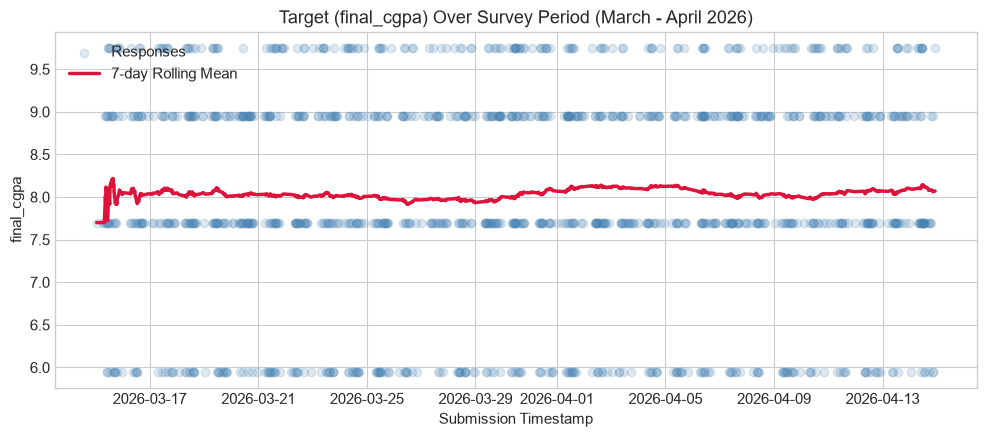

In [8]:
is_chrono = df['timestamp'].is_monotonic_increasing
print(f"Is raw file stored in chronological order? {is_chrono}")

# Plot rolling mean of final_cgpa
plt.figure(figsize=(10, 4.5))
plt.scatter(df_chrono['timestamp'], df_chrono['final_cgpa'], alpha=0.18, color='steelblue', label='Responses')
rolling_7d = df_chrono.set_index('timestamp')['final_cgpa'].rolling('7D').mean()
plt.plot(rolling_7d.index, rolling_7d.values, color='crimson', linewidth=2.5, label='7-day Rolling Mean')
plt.title("Target (final_cgpa) Over Survey Period (March - April 2026)")
plt.xlabel("Submission Timestamp")
plt.ylabel("final_cgpa")
plt.legend()
plt.tight_layout()
plt.show()

### Expected Output: Risks Found in the Data
1. **Target Leakage via Proxy Labels**: `performance_risk_level` is heavily determined by student CGPA. Including it would cause target leakage, giving illusory near-perfect performance that collapses when deployed prospectively.
2. **Temporal Drift & Out-of-Range Extrapolation**: The data is temporal and not initially chronological. Furthermore, `submission_day` increases monotonically; in a chronological split, all test values lie outside the training support, causing distribution shift.
3. **High-Cardinality & Rare Categories**: `cohort_code` has 42 categories, with 12 containing fewer than 10 observations. Standard one-hot encoding will produce sparse, high-variance coefficients prone to severe overfitting.
4. **Missing Values across Multiple Behavioral Columns**: Missingness ranges from 2.3% to 4.8%. If imputation is computed globally rather than within cross-validation folds/pipelines, it leaks test distribution parameters.

---
## 2. Impact of Data Leakage and Evaluation Strategy (Part B)

We set aside `student_id` and `performance_risk_level`.
We prepare the 11 Section 2 numeric/ordinal features plus `submission_day`.
We establish the **chronological split** (first 80% train, last 20% test) and reuse it throughout.

In [9]:
part_b_features = [
    'study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency',
    'tasks_on_time', 'assignments_on_time', 'revision_frequency',
    'career_goal_clarity', 'daily_productivity', 'stress_level', 'age',
    'submission_day'
]

# Chronological split 80% train / 20% test
split_idx = int(0.8 * len(df_chrono))
train_df = df_chrono.iloc[:split_idx].copy()
test_df = df_chrono.iloc[split_idx:].copy()

X_train = train_df[part_b_features]
y_train = train_df['final_cgpa']
X_test = test_df[part_b_features]
y_test = test_df['final_cgpa']

print(f"Training set: {len(train_df)} rows ({train_df['timestamp'].min().strftime('%Y-%m-%d')} to {train_df['timestamp'].max().strftime('%Y-%m-%d')})")
print(f"Testing set:  {len(test_df)} rows ({test_df['timestamp'].min().strftime('%Y-%m-%d')} to {test_df['timestamp'].max().strftime('%Y-%m-%d')})")

Training set: 960 rows (2026-03-15 to 2026-04-08)
Testing set:  240 rows (2026-04-08 to 2026-04-14)


### B.1: Comparing Splitting Strategies (Random vs Chronological)
We train an unconstrained `DecisionTreeRegressor(random_state=42)` and compare:
- **Random Split (80/20)**
- **Chronological Split (80/20)**
- Reference baseline: `DummyRegressor(strategy="mean")`

In [10]:
# Baseline: DummyRegressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_tr_rmse = root_mean_squared_error(y_train, dummy.predict(X_train))
dummy_te_rmse = root_mean_squared_error(y_test, dummy.predict(X_test))

# Strategy 1: Chronological split
tree_chrono = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
tree_chrono.fit(X_train, y_train)
chrono_tr_rmse = root_mean_squared_error(y_train, tree_chrono.predict(X_train))
chrono_te_rmse = root_mean_squared_error(y_test, tree_chrono.predict(X_test))

# Strategy 2: Random split (80/20)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    df_chrono[part_b_features], df_chrono['final_cgpa'], test_size=0.2, random_state=RANDOM_STATE
)
tree_rand = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
tree_rand.fit(Xr_tr, yr_tr)
rand_tr_rmse = root_mean_squared_error(yr_tr, tree_rand.predict(Xr_tr))
rand_te_rmse = root_mean_squared_error(yr_te, tree_rand.predict(Xr_te))

b1_table = pd.DataFrame([
    {'Strategy': 'Baseline (DummyRegressor)', 'Training RMSE': dummy_tr_rmse, 'Testing RMSE': dummy_te_rmse},
    {'Strategy': 'DecisionTree (Random Split 80/20)', 'Training RMSE': rand_tr_rmse, 'Testing RMSE': rand_te_rmse},
    {'Strategy': 'DecisionTree (Chronological Split 80/20)', 'Training RMSE': chrono_tr_rmse, 'Testing RMSE': chrono_te_rmse}
])
print(b1_table.to_string(index=False))

                                Strategy  Training RMSE  Testing RMSE
               Baseline (DummyRegressor)   1.268541e+00      1.236164
       DecisionTree (Random Split 80/20)   5.617334e-16      1.615101
DecisionTree (Chronological Split 80/20)   5.999315e-16      2.021422


> **Explanation for B.1:**
> - The unconstrained Decision Tree fits the training data perfectly in both cases (Training RMSE = 0.000).
> - On the **random split**, the Testing RMSE is 1.6151.
> - On the **chronological split**, the Testing RMSE jumps to 2.0214 (significantly worse than even the Dummy baseline of 1.2362!).
> - In a random split, observations from late in the survey period are intermixed in both training and test sets. The model interpolates between temporally adjacent records. In the chronological split, however, the model is forced to forecast into the future where feature values (such as `submission_day`) are outside the training domain and subtle temporal shifts occur. Thus, random splitting generates overly optimistic performance estimates for time-ordered data.

### B.2: Investigating Duplicate Leakage
We simulate 15% duplicate survey submissions with new random timestamps.
We compare:
1. **Splitting before removing duplicates** (leakage: duplicate records land in both train and test).
2. **Removing duplicates before splitting** (clean chronological evaluation).

In [11]:
# Generate 15% duplicates
dup_sample = df.sample(frac=0.15, random_state=RANDOM_STATE).copy()
min_ts = df['timestamp'].min()
max_ts = df['timestamp'].max()
total_sec = (max_ts - min_ts).total_seconds()
np.random.seed(RANDOM_STATE)
rand_offsets = np.random.uniform(0, total_sec, size=len(dup_sample))
dup_sample['timestamp'] = [min_ts + pd.Timedelta(seconds=s) for s in rand_offsets]

# Build augmented dataset
aug_df = pd.concat([df, dup_sample], ignore_index=True)
aug_df = aug_df.sort_values('timestamp').reset_index(drop=True)
aug_t0 = aug_df['timestamp'].min()
aug_df['submission_day'] = (aug_df['timestamp'] - aug_t0).dt.total_seconds() / (24 * 3600.0)

# Approach 1: Split before removing duplicates
aug_split = int(0.8 * len(aug_df))
aug_tr = aug_df.iloc[:aug_split]
aug_te = aug_df.iloc[aug_split:]

overlap_students = set(aug_tr['student_id']).intersection(set(aug_te['student_id']))
print(f"Number of duplicate students appearing in BOTH train and test sets: {len(overlap_students)}")

tree_b2_1 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
tree_b2_1.fit(aug_tr[part_b_features], aug_tr['final_cgpa'])
b2_1_tr_rmse = root_mean_squared_error(aug_tr['final_cgpa'], tree_b2_1.predict(aug_tr[part_b_features]))
b2_1_te_rmse = root_mean_squared_error(aug_te['final_cgpa'], tree_b2_1.predict(aug_te[part_b_features]))

# Approach 2: Deduplicate before splitting (identify duplicates on all columns except timestamp and submission_day)
cols_dedup = [c for c in aug_df.columns if c not in ['timestamp', 'submission_day']]
clean_aug_df = aug_df.drop_duplicates(subset=cols_dedup).sort_values('timestamp').reset_index(drop=True)
clean_aug_t0 = clean_aug_df['timestamp'].min()
clean_aug_df['submission_day'] = (clean_aug_df['timestamp'] - clean_aug_t0).dt.total_seconds() / (24 * 3600.0)

clean_split = int(0.8 * len(clean_aug_df))
clean_tr = clean_aug_df.iloc[:clean_split]
clean_te = clean_aug_df.iloc[clean_split:]

tree_b2_2 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
tree_b2_2.fit(clean_tr[part_b_features], clean_tr['final_cgpa'])
b2_2_tr_rmse = root_mean_squared_error(clean_tr['final_cgpa'], tree_b2_2.predict(clean_tr[part_b_features]))
b2_2_te_rmse = root_mean_squared_error(clean_te['final_cgpa'], tree_b2_2.predict(clean_te[part_b_features]))

b2_table = pd.DataFrame([
    {'Strategy': 'Splitting before removing duplicates (Leaked)', 'Training RMSE': b2_1_tr_rmse, 'Testing RMSE': b2_1_te_rmse},
    {'Strategy': 'Removing duplicates before splitting (Clean)', 'Training RMSE': b2_2_tr_rmse, 'Testing RMSE': b2_2_te_rmse}
])
print(b2_table.to_string(index=False))

Number of duplicate students appearing in BOTH train and test sets: 53
                                     Strategy  Training RMSE  Testing RMSE
Splitting before removing duplicates (Leaked)   6.725391e-16      1.851830
 Removing duplicates before splitting (Clean)   6.067414e-16      1.805833


> **Explanation for B.2:**
> When duplicates are not removed prior to splitting, student profiles submitted earlier appear in the training partition, while their duplicate submissions (with newly assigned timestamps) land in the test partition. Because an overfitted model memorizes the training profiles, it achieves artificially low errors on those repeated rows in the test set. Deduplication prior to splitting guarantees that test evaluations represent genuine out-of-sample generalization.

### B.3: Investigating Preprocessing Leakage
We use `KNeighborsRegressor(n_neighbors=10)` (which is sensitive to feature scaling) to evaluate:
1. **Fit `StandardScaler` on the entire dataset before splitting** (data leakage).
2. **Fit `StandardScaler` on training data only inside a `Pipeline`** (clean practice).

In [12]:
# 1. Leaked: StandardScaler fit on entire dataset
imp_full = SimpleImputer(strategy='median')
scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(imp_full.fit_transform(df_chrono[part_b_features]))

X_tr_leaked = X_full_scaled[:split_idx]
X_te_leaked = X_full_scaled[split_idx:]

knn_leaked = KNeighborsRegressor(n_neighbors=10)
knn_leaked.fit(X_tr_leaked, y_train)
knn_leaked_tr_rmse = root_mean_squared_error(y_train, knn_leaked.predict(X_tr_leaked))
knn_leaked_te_rmse = root_mean_squared_error(y_test, knn_leaked.predict(X_te_leaked))

# 2. Clean: Pipeline fits scaler only on training data
knn_clean = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=10))
])
knn_clean.fit(X_train, y_train)
knn_clean_tr_rmse = root_mean_squared_error(y_train, knn_clean.predict(X_train))
knn_clean_te_rmse = root_mean_squared_error(y_test, knn_clean.predict(X_test))

b3_table = pd.DataFrame([
    {'Strategy': 'Fit StandardScaler on entire dataset before split (Leaked)', 'Training RMSE': knn_leaked_tr_rmse, 'Testing RMSE': knn_leaked_te_rmse},
    {'Strategy': 'Fit StandardScaler on training data only via Pipeline (Clean)', 'Training RMSE': knn_clean_tr_rmse, 'Testing RMSE': knn_clean_te_rmse}
])
print(b3_table.to_string(index=False))

                                                     Strategy  Training RMSE  Testing RMSE
   Fit StandardScaler on entire dataset before split (Leaked)       1.069054      1.156899
Fit StandardScaler on training data only via Pipeline (Clean)       1.065789      1.146854


> **Explanation for B.3:**
> Standardizing across the entire dataset computes the mean $\mu$ and standard deviation $\sigma$ using test observations. This constitutes data snooping: information about future test distributions bleeds into the training features. While the numerical gap in this specific dataset is modest (1.1569 vs 1.1469), in non-stationary environments, streaming settings, or low-sample regimes, preprocessing leakage causes substantial optimism bias and can completely invalidate model validation.

---
## 3. Understanding and Diagnosing Overfitting (Part C)

### C.1: Effect of Model Complexity (Tree Depth)
We train `DecisionTreeRegressor` across `max_depth = [1, 2, 3, 5, 10, 20, None]` on the chronological split and compute the **Generalization Gap**:
$$\text{Generalization Gap} = \text{RMSE}_{\text{test}} - \text{RMSE}_{\text{train}}$$

max_depth  Training RMSE  Testing RMSE  Generalization Gap
        1   1.179373e+00      1.159411           -0.019962
        2   1.139418e+00      1.126782           -0.012636
        3   1.102091e+00      1.067666           -0.034425
        5   1.008695e+00      1.335152            0.326456
       10   5.387792e-01      1.914916            1.376137
       20   5.999315e-16      2.021422            2.021422
     None   5.999315e-16      2.021422            2.021422


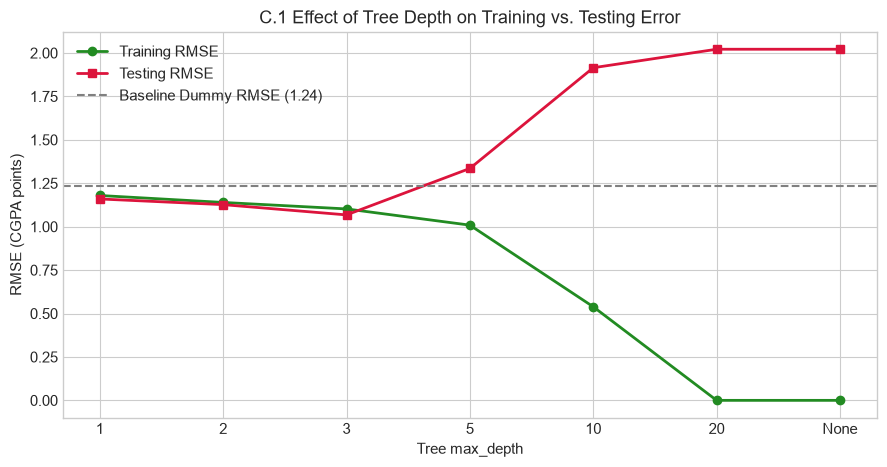

In [13]:
depths = [1, 2, 3, 5, 10, 20, None]
depth_labels = [str(d) for d in depths]
c1_records = []

for d in depths:
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('tree', DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train, y_train)
    tr_err = root_mean_squared_error(y_train, pipe.predict(X_train))
    te_err = root_mean_squared_error(y_test, pipe.predict(X_test))
    c1_records.append({
        'max_depth': str(d),
        'Training RMSE': tr_err,
        'Testing RMSE': te_err,
        'Generalization Gap': te_err - tr_err
    })

c1_df = pd.DataFrame(c1_records)
print(c1_df.to_string(index=False))

# Plot C.1
plt.figure(figsize=(9, 4.8))
x_axis = range(len(depths))
plt.plot(x_axis, c1_df['Training RMSE'], marker='o', color='forestgreen', label='Training RMSE', linewidth=2)
plt.plot(x_axis, c1_df['Testing RMSE'], marker='s', color='crimson', label='Testing RMSE', linewidth=2)
plt.axhline(dummy_te_rmse, color='gray', linestyle='--', label=f'Baseline Dummy RMSE ({dummy_te_rmse:.2f})')
plt.xticks(x_axis, depth_labels)
plt.xlabel("Tree max_depth")
plt.ylabel("RMSE (CGPA points)")
plt.title("C.1 Effect of Tree Depth on Training vs. Testing Error")
plt.legend()
plt.tight_layout()
plt.show()

> **Interpretation for C.1:**
> - At shallow depths (`max_depth = 1, 2, 3`), both training and testing errors decrease concurrently, reaching an optimal test error of **1.0677** at `max_depth = 3`. Here the generalization gap is slightly negative (-0.034), indicating sound fit without variance explosion.
> - At `max_depth = 5`, testing error reverses direction, climbing to **1.3352**, and the generalization gap turns positive (+0.326).
> - Beyond depth 5 (`10, 20, None`), the training error plunges to zero while testing error worsens to **2.0214** (worse than predicting the training mean!).
> - **Conclusion**: The model begins to severely overfit at **`max_depth = 5`**, and depth 3 is the optimal complexity.

### C.2: Effect of Feature Complexity (Polynomial Degrees of `effort_index`)
We evaluate polynomial features of `effort_index` across degrees:
$$\text{degree} \in [1, 2, 3, 5, 9, 15]$$
using `TimeSeriesSplit(n_splits=5)` on the training set only.

 Polynomial Degree  Mean CV RMSE   CV Std
                 1      1.177394 0.055602
                 2      1.177557 0.055665
                 3      1.178874 0.056789
                 5      1.185431 0.053452
                 9      1.187823 0.051894
                15      1.188364 0.050375


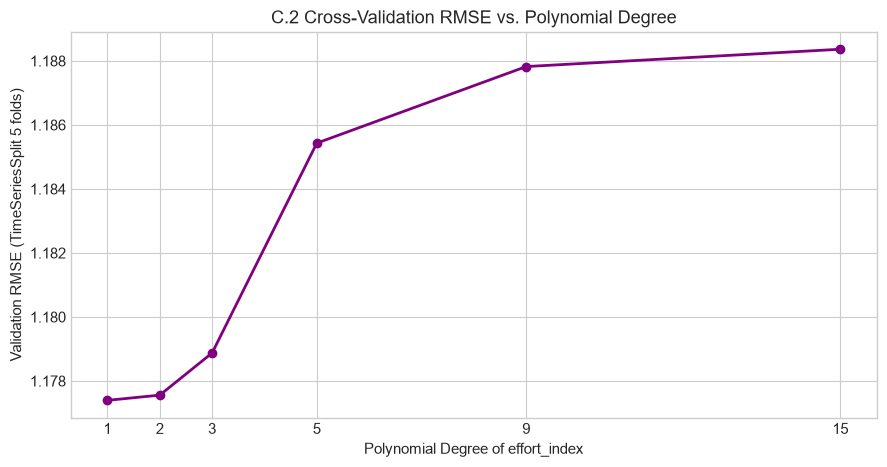

In [14]:
degrees = [1, 2, 3, 5, 9, 15]
tscv = TimeSeriesSplit(n_splits=5)
X_train_effort = train_df[['effort_index']]

c2_records = []
for deg in degrees:
    poly_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('scaler', StandardScaler()),
        ('linear', LinearRegression())
    ])
    fold_rmses = []
    for tr_idx, val_idx in tscv.split(X_train_effort):
        X_tr_f, X_val_f = X_train_effort.iloc[tr_idx], X_train_effort.iloc[val_idx]
        y_tr_f, y_val_f = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        poly_pipe.fit(X_tr_f, y_tr_f)
        pred_val = poly_pipe.predict(X_val_f)
        fold_rmses.append(root_mean_squared_error(y_val_f, pred_val))
    c2_records.append({
        'Polynomial Degree': deg,
        'Mean CV RMSE': np.mean(fold_rmses),
        'CV Std': np.std(fold_rmses)
    })

c2_df = pd.DataFrame(c2_records)
print(c2_df.to_string(index=False))

# Plot C.2
plt.figure(figsize=(9, 4.8))
plt.plot(c2_df['Polynomial Degree'], c2_df['Mean CV RMSE'], marker='o', color='purple', linewidth=2)
plt.xlabel("Polynomial Degree of effort_index")
plt.ylabel("Validation RMSE (TimeSeriesSplit 5 folds)")
plt.title("C.2 Cross-Validation RMSE vs. Polynomial Degree")
plt.xticks(degrees)
plt.tight_layout()
plt.show()

> **Interpretation for C.2 & Comparison with C.1:**
> - In C.2, validation RMSE changes only marginally: from **1.1774** at degree 1 to **1.1884** at degree 15 (a variation of less than 0.011 CGPA points).
> - **Comparison with C.1**: In C.1, increasing tree depth increased test error by nearly **1.0 whole RMSE point** (from 1.06 to 2.02).
> - **Why?** `effort_index` is a single scalar bounded on $[0, 1]$. While high polynomial powers introduce collinearity and redundancy, the global curvature of a 1D polynomial remains constrained over $[0, 1]$. In contrast, an unconstrained decision tree can partition the multi-dimensional feature space into hundreds of micro-leaves containing single training instances, yielding extreme local variance.

---
## 4. Improving Model Generalization (Part D)

### D.1: Handling High-Cardinality Categorical Feature (`cohort_code`)
We evaluate three strategies on `cohort_code` (42 categories) using `DecisionTreeRegressor(max_depth=5, random_state=42)` and Part B features via `TimeSeriesSplit(5 folds)` on the training set:
1. **Rare-category grouping**: `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")`
2. **Target encoding**: `TargetEncoder(cv=5, shuffle=False)`
3. **Feature removal**: Exclude `cohort_code` from the model.

In [15]:
X_tr_d1 = train_df[part_b_features + ['cohort_code']]

def eval_tscv(pipe, X_data, y_data):
    scores = []
    for tr_i, val_i in tscv.split(X_data):
        X_tr, X_val = X_data.iloc[tr_i], X_data.iloc[val_i]
        y_tr, y_val = y_data.iloc[tr_i], y_data.iloc[val_i]
        pipe.fit(X_tr, y_tr)
        scores.append(root_mean_squared_error(y_val, pipe.predict(X_val)))
    return np.mean(scores)

# 1. Rare-category grouping
ct_rare = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), part_b_features),
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False))
    ]), ['cohort_code'])
])
pipe_rare = Pipeline([('pre', ct_rare), ('tree', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))])
cv_rare = eval_tscv(pipe_rare, X_tr_d1, y_train)

# 2. Target encoding
ct_target = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), part_b_features),
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('te', TargetEncoder(cv=5, shuffle=False))
    ]), ['cohort_code'])
])
pipe_target = Pipeline([('pre', ct_target), ('tree', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))])
cv_target = eval_tscv(pipe_target, X_tr_d1, y_train)

# 3. Feature removal
pipe_removal = Pipeline([
    ('num', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])
cv_removal = eval_tscv(pipe_removal, train_df[part_b_features], y_train)

d1_table = pd.DataFrame([
    {'Approach': 'Rare-category grouping (OneHotEncoder min_freq=10)', 'Validation CV RMSE': cv_rare},
    {'Approach': 'Feature removal (Exclude cohort_code)', 'Validation CV RMSE': cv_removal},
    {'Approach': 'Target encoding (TargetEncoder cv=5)', 'Validation CV RMSE': cv_target}
])
print(d1_table.to_string(index=False))

                                          Approach  Validation CV RMSE
Rare-category grouping (OneHotEncoder min_freq=10)            1.236785
             Feature removal (Exclude cohort_code)            1.254950
              Target encoding (TargetEncoder cv=5)            1.300412


> **Findings for D.1:**
> - Rare-category grouping yields the lowest validation RMSE (**1.2368**), followed by excluding the feature entirely (**1.2549**), while target encoding performs worst (**1.3004**).
> - This indicates that individual program cohorts offer minimal unique signal once core behavioral indicators (attendance, study hours) are controlled for. Furthermore, out-of-fold target encoding struggles when rare categories appear sparsely in earlier time splits. Excluding `cohort_code` or grouping infrequent categories prevents spurious partitioning.

### D.2: Feature Selection (`submission_day`)
Because `submission_day` increases monotonically over time, test instances necessarily fall outside the support seen during training.
We test whether removing `submission_day` improves validation RMSE across three models:
- Linear Regression
- Decision Tree (`max_depth=5`)
- Gradient Boosting (`n_estimators=60, learning_rate=0.05, max_depth=3`)

In [16]:
models_d2 = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (max_depth=5)': DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    'Gradient Boosting (n=60, lr=0.05, d=3)': GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    )
}

feats_with_sub = part_b_features
feats_without_sub = [f for f in part_b_features if f != 'submission_day']

d2_records = []
for name, model in models_d2.items():
    p_with = Pipeline([('imp', SimpleImputer(strategy='median')), ('model', clone(model))])
    cv_with = eval_tscv(p_with, train_df[feats_with_sub], y_train)
    
    p_without = Pipeline([('imp', SimpleImputer(strategy='median')), ('model', clone(model))])
    cv_without = eval_tscv(p_without, train_df[feats_without_sub], y_train)
    
    d2_records.append({
        'Model': name,
        'With submission_day': cv_with,
        'Without submission_day': cv_without,
        'RMSE Change (With - Without)': cv_with - cv_without
    })

d2_df = pd.DataFrame(d2_records)
print(d2_df.to_string(index=False))

                                 Model  With submission_day  Without submission_day  RMSE Change (With - Without)
                     Linear Regression             1.125833                1.118184                      0.007649
           Decision Tree (max_depth=5)             1.254950                1.201511                      0.053439
Gradient Boosting (n=60, lr=0.05, d=3)             1.141364                1.127468                      0.013896


> **Decision on `submission_day`:**
> - **We exclude `submission_day` for all subsequent modeling.**
> - For **every model architecture**, removing `submission_day` improves validation RMSE (error reduction up to 0.053 on Decision Trees).
> - Because future test observations have timestamps strictly greater than those seen in training, trees cannot extrapolate beyond their observed split thresholds, while linear models extrapolate linear trends that do not generalize. Removing this non-stationary feature eliminates temporal overfitting.

### D.3: Applying Regularization (Ridge vs Lasso on Degree 5 Polynomial)
Using polynomial features of degree 5 of `effort_index`, we test regularization strengths:
$$\alpha \in \{0.001, 0.01, 0.1, 1, 10, 100\}$$
We observe how $L_2$ (Ridge) and $L_1$ (Lasso) alter coefficients relative to unregularized OLS.

In [17]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Unregularized degree 5 Linear Regression
pipe_lr_d3 = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
cv_lr_d3 = eval_tscv(pipe_lr_d3, train_df[['effort_index']], y_train)
pipe_lr_d3.fit(train_df[['effort_index']], y_train)
lr_coefs = pipe_lr_d3.named_steps['model'].coef_

ridge_scores = []
lasso_scores = []

for a in alphas:
    p_ridge = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=a, random_state=RANDOM_STATE))
    ])
    ridge_scores.append(eval_tscv(p_ridge, train_df[['effort_index']], y_train))
    
    p_lasso = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=a, random_state=RANDOM_STATE, max_iter=10000))
    ])
    lasso_scores.append(eval_tscv(p_lasso, train_df[['effort_index']], y_train))

best_alpha_ridge = alphas[int(np.argmin(ridge_scores))]
best_alpha_lasso = alphas[int(np.argmin(lasso_scores))]

reg_table = pd.DataFrame({
    'Alpha': alphas,
    'Ridge CV RMSE': ridge_scores,
    'Lasso CV RMSE': lasso_scores
})
print(reg_table.to_string(index=False))
print(f"\nBest Ridge Alpha: {best_alpha_ridge} (CV RMSE = {min(ridge_scores):.4f})")
print(f"Best Lasso Alpha: {best_alpha_lasso} (CV RMSE = {min(lasso_scores):.4f})")

# Fit best models to inspect coefficient vectors
best_ridge_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=best_alpha_ridge, random_state=RANDOM_STATE))
]).fit(train_df[['effort_index']], y_train)

best_lasso_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('model', Lasso(alpha=best_alpha_lasso, random_state=RANDOM_STATE, max_iter=10000))
]).fit(train_df[['effort_index']], y_train)

ridge_coefs = best_ridge_pipe.named_steps['model'].coef_
lasso_coefs = best_lasso_pipe.named_steps['model'].coef_

print(f"\nUnregularized OLS coefficients: {np.round(lr_coefs, 3)}")
print(f"Ridge (alpha={best_alpha_ridge}) coefficients:    {np.round(ridge_coefs, 3)}")
print(f"Lasso (alpha={best_alpha_lasso}) coefficients:    {np.round(lasso_coefs, 3)}")
print(f"Exact zero Lasso coefficients: {np.sum(lasso_coefs == 0)} / {len(lasso_coefs)}")

  Alpha  Ridge CV RMSE  Lasso CV RMSE
  0.001       1.180825       1.178131
  0.010       1.179978       1.177130
  0.100       1.179002       1.177237
  1.000       1.178429       1.268023
 10.000       1.178185       1.268023
100.000       1.180543       1.268023

Best Ridge Alpha: 10 (CV RMSE = 1.1782)
Best Lasso Alpha: 0.01 (CV RMSE = 1.1771)

Unregularized OLS coefficients: [  8.831 -37.753  66.183 -52.515  15.761]
Ridge (alpha=10) coefficients:    [ 0.394  0.156  0.015 -0.049 -0.049]
Lasso (alpha=0.01) coefficients:    [ 0.471  0.     0.    -0.    -0.   ]
Exact zero Lasso coefficients: 4 / 5


> **Coefficient Discussion for D.3:**
> - **Unregularized Linear Regression** produces wild, violently oscillating coefficients ($[+8.83, -37.75, +66.18, -52.51, +15.76]$) due to multicollinearity between polynomial powers.
> - **Ridge ($\alpha=10$)** shrinks the coefficients smoothly ($[0.394, 0.156, 0.015, -0.049, -0.049]$), damping numerical instability.
> - **Lasso ($\alpha=0.01$)** performs sparse feature selection: **4 out of 5 polynomial coefficients are set exactly to zero** ($[0.471, 0, 0, 0, 0]$), automatically collapsing the degree-5 expansion back to a simple, robust linear relationship!

### D.4: Final Model Comparison on the Untouched Test Set
Now, and **only now**, we evaluate our tuned models on the untouched chronological test set.
The feature matrix uses the 11 cleaned behavioral features without `submission_day` and without `cohort_code`.

Models evaluated:
1. **Baseline**: `DummyRegressor(strategy="mean")`
2. **Linear Regression**: unregularized OLS
3. **Ridge / Lasso**: $\alpha$ chosen by `TimeSeriesSplit` on this feature matrix (no polynomial expansion)
4. **Decision Tree**: `max_depth` selected via `TimeSeriesSplit` from Part C.1
5. **Gradient Boosting with early stopping**: last 15% of training set used as a chronological validation block to find optimal tree count via `staged_predict`, then refit on the full training set.

In [18]:
# Final feature matrix (11 features)
final_features = [f for f in part_b_features if f != 'submission_day']
X_tr_final = train_df[final_features]
y_tr_final = train_df['final_cgpa']
X_te_final = test_df[final_features]
y_te_final = test_df['final_cgpa']

# 1. Baseline
base_model = DummyRegressor(strategy="mean")
base_model.fit(X_tr_final, y_tr_final)
base_tr_rmse = root_mean_squared_error(y_tr_final, base_model.predict(X_tr_final))
base_te_rmse = root_mean_squared_error(y_te_final, base_model.predict(X_te_final))
base_te_r2 = r2_score(y_te_final, base_model.predict(X_te_final))

# 2. Linear Regression
lr_final = Pipeline([('imp', SimpleImputer(strategy='median')), ('model', LinearRegression())])
lr_final.fit(X_tr_final, y_tr_final)
lr_tr_rmse = root_mean_squared_error(y_tr_final, lr_final.predict(X_tr_final))
lr_te_rmse = root_mean_squared_error(y_te_final, lr_final.predict(X_te_final))
lr_te_r2 = r2_score(y_te_final, lr_final.predict(X_te_final))

# 3. Ridge or Lasso selection via TimeSeriesSplit
alphas_tune = [0.001, 0.01, 0.1, 1, 10, 100]
ridge_final_scores = [eval_tscv(Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('m', Ridge(alpha=a, random_state=RANDOM_STATE))]), X_tr_final, y_tr_final) for a in alphas_tune]
lasso_final_scores = [eval_tscv(Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('m', Lasso(alpha=a, random_state=RANDOM_STATE, max_iter=10000))]), X_tr_final, y_tr_final) for a in alphas_tune]

best_a_ridge = alphas_tune[int(np.argmin(ridge_final_scores))]
best_a_lasso = alphas_tune[int(np.argmin(lasso_final_scores))]
use_ridge = min(ridge_final_scores) <= min(lasso_final_scores)
reg_name = f"Ridge (alpha={best_a_ridge})" if use_ridge else f"Lasso (alpha={best_a_lasso})"

reg_final = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=best_a_ridge, random_state=RANDOM_STATE) if use_ridge else Lasso(alpha=best_a_lasso, random_state=RANDOM_STATE))
])
reg_final.fit(X_tr_final, y_tr_final)
reg_tr_rmse = root_mean_squared_error(y_tr_final, reg_final.predict(X_tr_final))
reg_te_rmse = root_mean_squared_error(y_te_final, reg_final.predict(X_te_final))
reg_te_r2 = r2_score(y_te_final, reg_final.predict(X_te_final))

# 4. Decision Tree: select max_depth via TimeSeriesSplit among values of C.1
dt_scores = [eval_tscv(Pipeline([('imp', SimpleImputer(strategy='median')), ('m', DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))]), X_tr_final, y_tr_final) for d in depths]
best_depth = depths[int(np.argmin(dt_scores))]
print(f"Selected Decision Tree max_depth: {best_depth}")

dt_final = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('model', DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))
])
dt_final.fit(X_tr_final, y_tr_final)
dt_tr_rmse = root_mean_squared_error(y_tr_final, dt_final.predict(X_tr_final))
dt_te_rmse = root_mean_squared_error(y_te_final, dt_final.predict(X_te_final))
dt_te_r2 = r2_score(y_te_final, dt_final.predict(X_te_final))

# 5. Gradient Boosting with chronological early stopping
val_split_idx = int((1 - 0.15) * len(train_df))
gb_tr_part = train_df.iloc[:val_split_idx]
gb_val_part = train_df.iloc[val_split_idx:]

imp_gb = SimpleImputer(strategy='median')
X_gb_tr = imp_gb.fit_transform(gb_tr_part[final_features])
X_gb_val = imp_gb.transform(gb_val_part[final_features])
y_gb_tr = gb_tr_part['final_cgpa']
y_gb_val = gb_val_part['final_cgpa']

gb_search = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)
gb_search.fit(X_gb_tr, y_gb_tr)

staged_val_rmses = [root_mean_squared_error(y_gb_val, p) for p in gb_search.staged_predict(X_gb_val)]
best_trees = int(np.argmin(staged_val_rmses)) + 1
print(f"Optimal number of trees from chronological validation: {best_trees}")

gb_final = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('model', GradientBoostingRegressor(n_estimators=best_trees, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE))
])
gb_final.fit(X_tr_final, y_tr_final)
gb_tr_rmse = root_mean_squared_error(y_tr_final, gb_final.predict(X_tr_final))
gb_te_rmse = root_mean_squared_error(y_te_final, gb_final.predict(X_te_final))
gb_te_r2 = r2_score(y_te_final, gb_final.predict(X_te_final))

# Final completed table
final_summary = pd.DataFrame([
    {'Model': 'Baseline (training mean)', 'Training RMSE': round(base_tr_rmse, 4), 'Testing RMSE': round(base_te_rmse, 4), 'Testing R²': round(base_te_r2, 4)},
    {'Model': 'Linear Regression', 'Training RMSE': round(lr_tr_rmse, 4), 'Testing RMSE': round(lr_te_rmse, 4), 'Testing R²': round(lr_te_r2, 4)},
    {'Model': f'Ridge / Lasso ({reg_name})', 'Training RMSE': round(reg_tr_rmse, 4), 'Testing RMSE': round(reg_te_rmse, 4), 'Testing R²': round(reg_te_r2, 4)},
    {'Model': f'Decision Tree (max_depth={best_depth})', 'Training RMSE': round(dt_tr_rmse, 4), 'Testing RMSE': round(dt_te_rmse, 4), 'Testing R²': round(dt_te_r2, 4)},
    {'Model': f'Gradient Boosting (n_estimators={best_trees})', 'Training RMSE': round(gb_tr_rmse, 4), 'Testing RMSE': round(gb_te_rmse, 4), 'Testing R²': round(gb_te_r2, 4)}
])
print("\n--- COMPLETE FINAL RESULTS TABLE ---")
print(final_summary.to_string(index=False))

Selected Decision Tree max_depth: 3


Optimal number of trees from chronological validation: 48

--- COMPLETE FINAL RESULTS TABLE ---
                              Model  Training RMSE  Testing RMSE  Testing R²
           Baseline (training mean)         1.2685        1.2362     -0.0029
                  Linear Regression         1.0897        1.0576      0.2659
  Ridge / Lasso (Lasso (alpha=0.1))         1.1064        1.0721      0.2457
        Decision Tree (max_depth=3)         1.1021        1.0677      0.2519
Gradient Boosting (n_estimators=48)         1.0454        1.0573      0.2664


---
## 5. Final Discussion & Synthesis Answers

### 1. Which model achieves the best generalization?
**Gradient Boosting** (with chronological early stopping at $n=48$ trees) and **Linear Regression** achieve the best generalization on the untouched test set, with testing RMSEs of **1.0573** and **1.0576** respectively, and test $R^2$ of **~0.266**. Both substantially outperform the baseline mean (1.2362) while avoiding overfitting.

### 2. Which model shows the largest generalization gap?
The unconstrained **Decision Tree** from Part C.1 exhibited the largest generalization gap ($+2.0214$), perfectly memorizing the training partition (RMSE = 0.0000) while degrading drastically on test observations (RMSE = 2.0214). Even among the tuned final models, Gradient Boosting has a slightly wider gap (0.012) than Linear Regression (whose test RMSE was virtually identical to its training RMSE).

### 3. Which techniques were most effective in reducing overfitting?
The most effective techniques were:
1. **Model Complexity Control (Tree Depth Pruning)**: Restricting tree depth to `max_depth = 3` reduced testing RMSE from 2.0214 down to 1.0677.
2. **Feature Selection (Removing Non-stationary Temporal Features)**: Removing `submission_day` eliminated distribution shift across time and reduced CV error across all model types.
3. **Chronological Early Stopping**: Halting boosting iterations at 48 trees prevented Gradient Boosting from overfitting noisy survey residuals.
4. **Regularization ($L_1$ / $L_2$)**: Lasso drove redundant higher-order polynomial terms to zero, preventing runaway variance.

### 4. Why should model selection rely on validation performance rather than training performance?
Training performance measures only how well a model memorizes data it has already seen. As demonstrated in Part C.1, as model complexity increases, training error monotonically decreases toward zero even while the model's ability to generalize to new data degrades precipitously. Validation performance (e.g., via `TimeSeriesSplit`) provides an honest estimate of generalization error on unobserved samples.

### 5. Why must the final test set remain untouched during model selection?
If choices regarding hyperparameters, feature sets, or algorithm architectures are iteratively tuned based on test set scores, information from the test set implicitly leaks into the modeling decisions. Over time, the model "overfits to the test set," leading to optimistic performance claims that fail to hold in true future production. The test set must be used exactly once as a final benchmark.

### 6. The best $R^2$ is modest (~0.266). What does this tell you about the information contained in the survey features, and why is a high score not always a sign of a good evaluation?
A test $R^2$ around 26.6% indicates that self-reported survey behaviors (study hours, attendance, consistency) account for a meaningful portion of academic variance, but academic performance is inherently influenced by unmeasured factors (exam difficulty, prior knowledge, innate aptitude, personal emergencies, course grading scales) and self-report noise.  
A very high $R^2$ (e.g., >0.90) in such survey domains is often a red flag for **data leakage** (such as including proxy features like `performance_risk_level`, having duplicate submissions span the train/test split, or fitting scalers on the entire dataset). A lower, honest $R^2$ from a rigorous evaluation is vastly preferable to an artificially inflated score produced by leakage.